In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import multiprocessing
import itertools
import warnings
from collections import Counter
from pandas.api.types import is_numeric_dtype

# Machine Learning Models
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
import lightgbm as lgb
from xgboost import XGBClassifier

# Metrics & Evaluation
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, precision_recall_curve,
    roc_curve, r2_score, mean_squared_error
)
from sklearn.inspection import permutation_importance

# Handling Imbalanced Data
from imblearn.over_sampling import SMOTE, ADASYN

# SHAP for model interpretability
import shap

# Suppress warnings
warnings.filterwarnings("ignore")

In [9]:
# Load the training dataset directly from a public source to avoid Google Drive authentication issues
import pandas as pd

train_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

columns = ["duration","protocoltype","service","flag","srcbytes","dstbytes","land", "wrongfragment","urgent","hot","numfailedlogins","loggedin", "numcompromised","rootshell","suattempted","numroot","numfilecreations", "numshells","numaccessfiles","numoutboundcmds","ishostlogin",
"isguestlogin","count","srvcount","serrorrate", "srvserrorrate",
"rerrorrate","srvrerrorrate","samesrvrate", "diffsrvrate", "srvdiffhostrate","dsthostcount","dsthostsrvcount","dsthostsamesrvrate", "dsthostdiffsrvrate","dsthostsamesrcportrate",
"dsthostsrvdiffhostrate","dsthostserrorrate","dsthostsrvserrorrate",
"dsthostrerrorrate","dsthostsrvrerrorrate","attack", "lastflag"]

df = pd.read_csv(train_url, sep=",", names=columns)
df.head()

,duration,protocoltype,service,flag,srcbytes,dstbytes,land,wrongfragment,urgent,hot,...,dsthostsamesrvrate,dsthostdiffsrvrate,dsthostsamesrcportrate,dsthostsrvdiffhostrate,dsthostserrorrate,dsthostsrvserrorrate,dsthostrerrorrate,dsthostsrvrerrorrate,attack,lastflag
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [10]:
df.shape

(125973, 43)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   duration                125973 non-null  int64  
 1   protocoltype            125973 non-null  object 
 2   service                 125973 non-null  object 
 3   flag                    125973 non-null  object 
 4   srcbytes                125973 non-null  int64  
 5   dstbytes                125973 non-null  int64  
 6   land                    125973 non-null  int64  
 7   wrongfragment           125973 non-null  int64  
 8   urgent                  125973 non-null  int64  
 9   hot                     125973 non-null  int64  
 10  numfailedlogins         125973 non-null  int64  
 11  loggedin                125973 non-null  int64  
 12  numcompromised          125973 non-null  int64  
 13  rootshell               125973 non-null  int64  
 14  suattempted         

In [12]:
df.describe()

,duration,srcbytes,dstbytes,land,wrongfragment,urgent,hot,numfailedlogins,loggedin,numcompromised,...,dsthostsrvcount,dsthostsamesrvrate,dsthostdiffsrvrate,dsthostsamesrcportrate,dsthostsrvdiffhostrate,dsthostserrorrate,dsthostsrvserrorrate,dsthostrerrorrate,dsthostsrvrerrorrate,lastflag
count,125973.00000,1.259730e+05,1.259730e+05,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,...,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000
mean,287.14465,4.556674e+04,1.977911e+04,0.000198,0.022687,0.000111,0.204409,0.001222,0.395736,0.279250,...,115.653005,0.521242,0.082951,0.148379,0.032542,0.284452,0.278485,0.118832,0.120240,19.504060
std,2604.51531,5.870331e+06,4.021269e+06,0.014086,0.253530,0.014366,2.149968,0.045239,0.489010,23.942042,...,110.702741,0.448949,0.188922,0.308997,0.112564,0.444784,0.445669,0.306557,0.319459,2.291503
min,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000
50%,0.00000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,63.000000,0.510000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
75%,0.00000,2.760000e+02,5.160000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000,21.000000
max,42908.00000,1.379964e+09,1.309937e+09,1.000000,3.000000,3.000000,77.000000,5.000000,1.000000,7479.000000,...,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,21.000000


As we can see 'land', 'urgent', 'numfailedlogins', 'numoutboundcmds' have mostly zero values so we can drop these columns.

In [16]:
# Drop unnecessary columns (errors='ignore' prevents KeyErrors on re-runs)
df.drop(['land','urgent','numfailedlogins','numoutboundcmds'], axis=1, inplace=True, errors='ignore')

In [18]:
df.isna().sum()

,0
duration,0
protocoltype,0
service,0
flag,0
srcbytes,0
dstbytes,0
wrongfragment,0
hot,0
loggedin,0
numcompromised,0


In [19]:
df.select_dtypes(exclude=[np.number])

,protocoltype,service,flag,attack
0,tcp,ftp_data,SF,normal
1,udp,other,SF,normal
2,tcp,private,S0,neptune
3,tcp,http,SF,normal
4,tcp,http,SF,normal
...,...,...,...,...
125968,tcp,private,S0,neptune
125969,udp,private,SF,normal
125970,tcp,smtp,SF,normal
125971,tcp,klogin,S0,neptune


For focussing on Binomial Classification for this dataset, we can make all other classes other than normal as 'attack'.

In [23]:
df['attack'].loc[df['attack']!='normal']='attack'

In [24]:
le=LabelEncoder()

In [25]:
df['protocoltype']=le.fit_transform(df['protocoltype'])
df['service']=le.fit_transform(df['service'])
df['flag']=le.fit_transform(df['flag'])
df['attack']=le.fit_transform(df['attack'])

In [26]:
df['attack'].value_counts()

,count
attack,
1,67343
0,58630


# Correlation Matrix to get rid of noise data

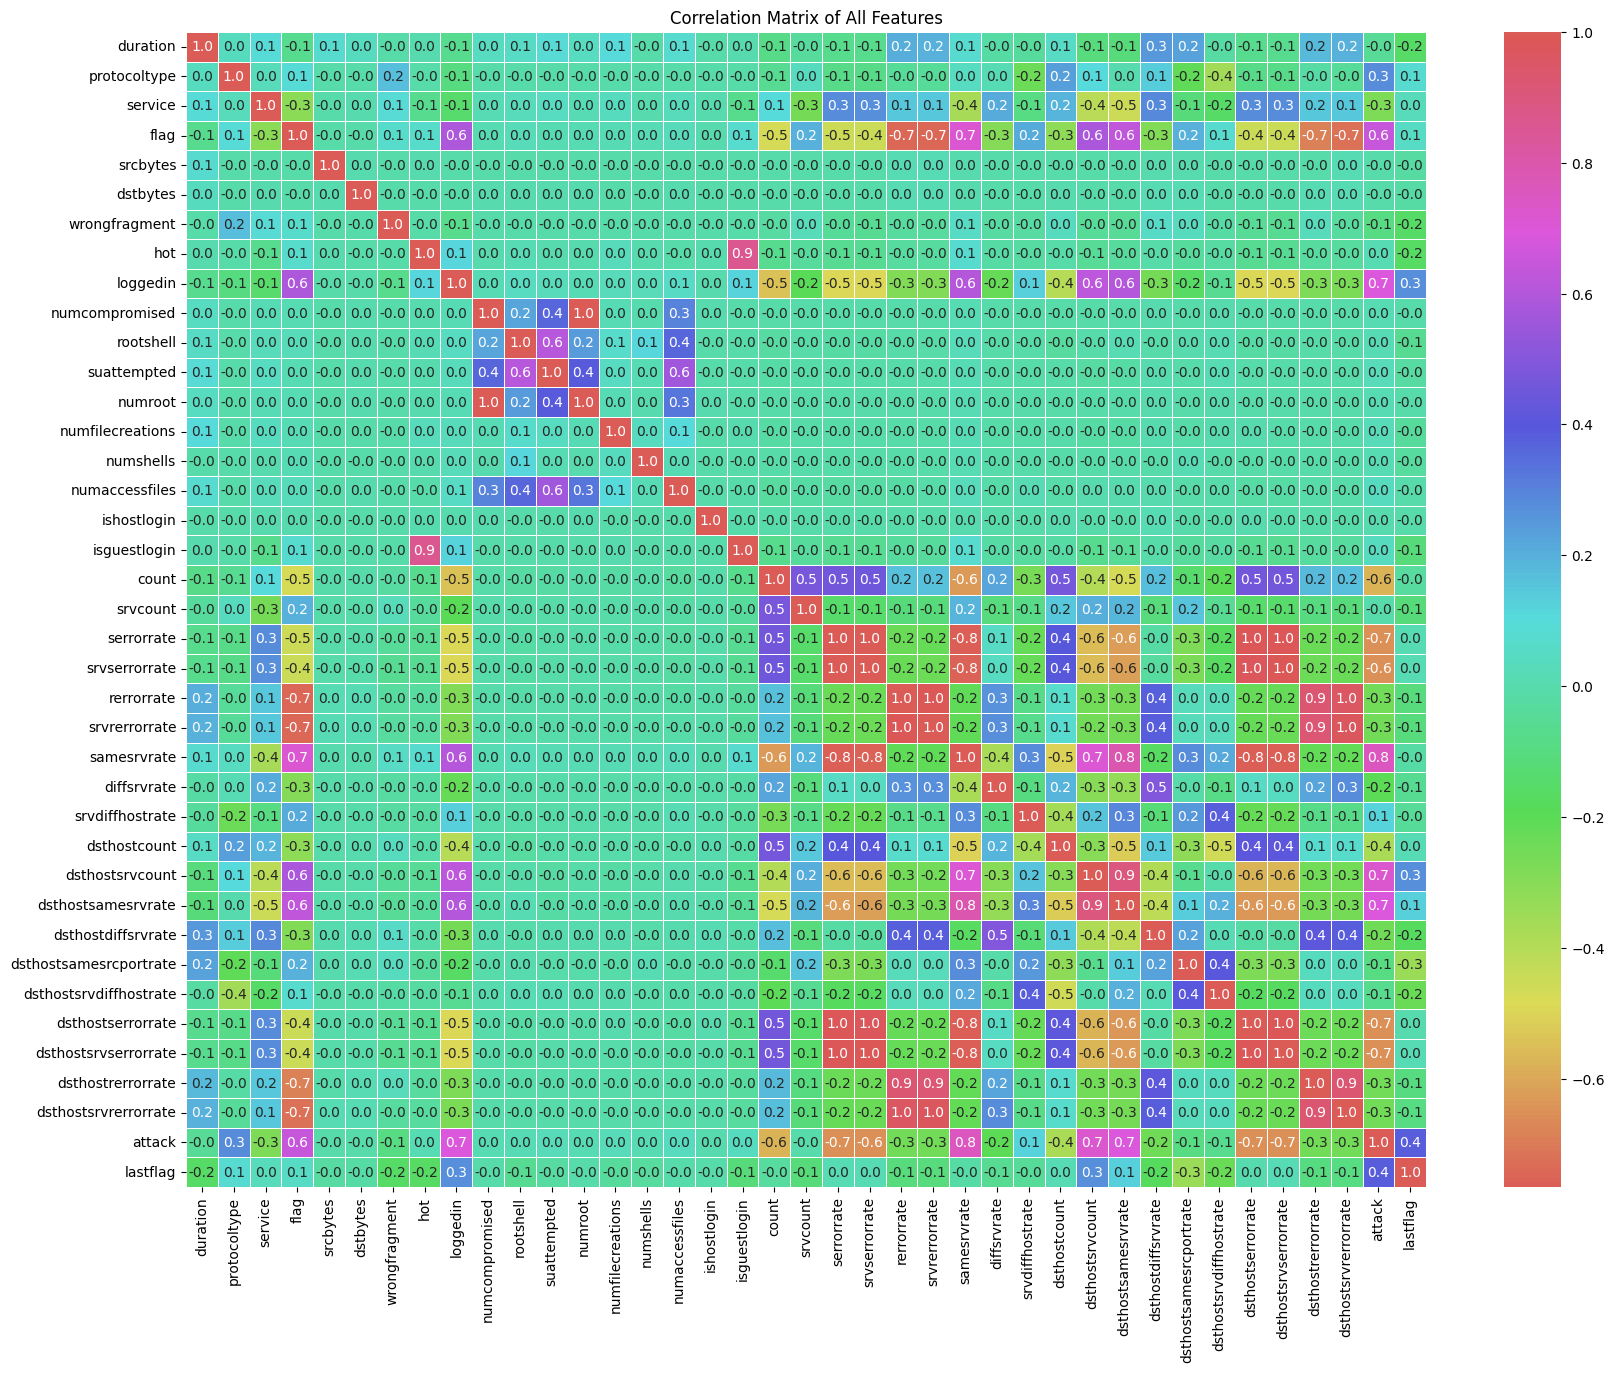

In [27]:
# Calculate the correlation matrix
corr_matrix = df.corr(numeric_only=True)

cmap_husl = sns.hls_palette(as_cmap=True)
#cmap_husl = sns.husl_palette(as_cmap=True)

# Plot the correlation matrix with values using the Husl colormap
plt.figure(figsize=(20, 15))
sns.heatmap(corr_matrix, annot=True, fmt=".1f", cmap=cmap_husl, linewidths=0.5)
plt.title('Correlation Matrix of All Features')
plt.show()

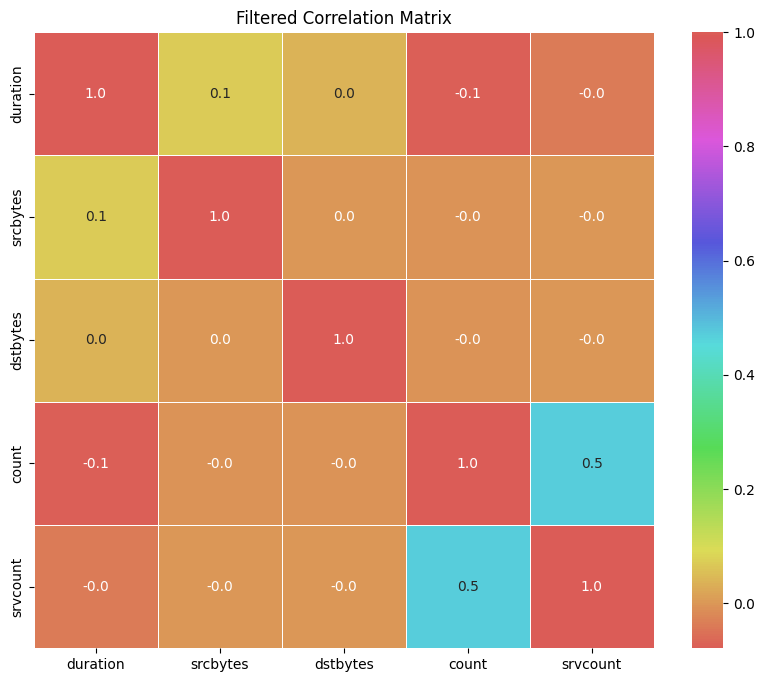

In [28]:
# Filter the correlation matrix for specific features that is important
selected_features = ['duration', 'srcbytes', 'dstbytes', 'count', 'srvcount']
filtered_corr_matrix = df[selected_features].corr()

# Plot the filtered correlation matrix
plt.figure(figsize=(10, 8))
cmap_husl = sns.hls_palette(as_cmap=True)
sns.heatmap(filtered_corr_matrix, annot=True, fmt=".1f", cmap= cmap_husl, linewidths=0.5)
plt.title('Filtered Correlation Matrix')
plt.show()

In [30]:
X=df.drop(['attack'],axis=1)
y=df['attack']

Text(0, 0.5, 'Count')

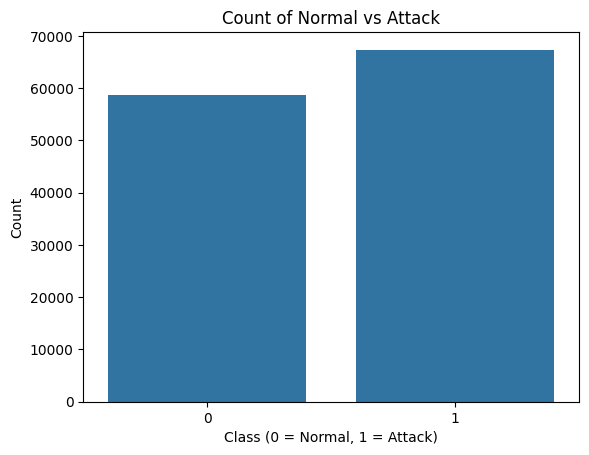

In [31]:
sns.countplot(x='attack', data=df)
plt.title("Count of Normal vs Attack")
plt.xlabel("Class (0 = Normal, 1 = Attack)")
plt.ylabel("Count")

In [32]:
print("Class distribution: {}".format(Counter(y)))

Class distribution: Counter({1: 67343, 0: 58630})


In [33]:
scaler = StandardScaler()
scaler.fit(X)
X_transformed = scaler.transform(X)

# Load & Read The Test Data

In [34]:
# Load the test dataset directly from a public source
test_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"

test_df = pd.read_csv(test_url, sep=",", names=columns)
test_df.head()

,duration,protocoltype,service,flag,srcbytes,dstbytes,land,wrongfragment,urgent,hot,...,dsthostsamesrvrate,dsthostdiffsrvrate,dsthostsamesrcportrate,dsthostsrvdiffhostrate,dsthostserrorrate,dsthostsrvserrorrate,dsthostrerrorrate,dsthostsrvrerrorrate,attack,lastflag
0,0,tcp,private,REJ,0,0,0,0,0,0,...,0.04,0.06,0.00,0.00,0.0,0.0,1.00,1.00,neptune,21
1,0,tcp,private,REJ,0,0,0,0,0,0,...,0.00,0.06,0.00,0.00,0.0,0.0,1.00,1.00,neptune,21
2,2,tcp,ftp_data,SF,12983,0,0,0,0,0,...,0.61,0.04,0.61,0.02,0.0,0.0,0.00,0.00,normal,21
3,0,icmp,eco_i,SF,20,0,0,0,0,0,...,1.00,0.00,1.00,0.28,0.0,0.0,0.00,0.00,saint,15
4,1,tcp,telnet,RSTO,0,15,0,0,0,0,...,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71,mscan,11


In [35]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22544 entries, 0 to 22543
Data columns (total 43 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   duration                22544 non-null  int64  
 1   protocoltype            22544 non-null  object 
 2   service                 22544 non-null  object 
 3   flag                    22544 non-null  object 
 4   srcbytes                22544 non-null  int64  
 5   dstbytes                22544 non-null  int64  
 6   land                    22544 non-null  int64  
 7   wrongfragment           22544 non-null  int64  
 8   urgent                  22544 non-null  int64  
 9   hot                     22544 non-null  int64  
 10  numfailedlogins         22544 non-null  int64  
 11  loggedin                22544 non-null  int64  
 12  numcompromised          22544 non-null  int64  
 13  rootshell               22544 non-null  int64  
 14  suattempted             22544 non-null

In [36]:
test_df.shape

(22544, 43)

In [37]:
test_df.select_dtypes(exclude=[np.number])

,protocoltype,service,flag,attack
0,tcp,private,REJ,neptune
1,tcp,private,REJ,neptune
2,tcp,ftp_data,SF,normal
3,icmp,eco_i,SF,saint
4,tcp,telnet,RSTO,mscan
...,...,...,...,...
22539,tcp,smtp,SF,normal
22540,tcp,http,SF,normal
22541,tcp,http,SF,back
22542,udp,domain_u,SF,normal


In [38]:
test_df['attack'].loc[test_df['attack']!='normal']='attack'

In [39]:
test_df['protocoltype']=le.fit_transform(test_df['protocoltype'])
test_df['service']=le.fit_transform(test_df['service'])
test_df['flag']=le.fit_transform(test_df['flag'])
test_df['attack']=le.fit_transform(test_df['attack'])

In [40]:
# Drop unnecessary columns
test_df.drop(['land','urgent','numfailedlogins','numoutboundcmds'],axis=1,inplace=True)

In [41]:
X_test=test_df.drop(['attack'],axis=1)
y_test=test_df['attack']

Text(0, 0.5, 'Count')

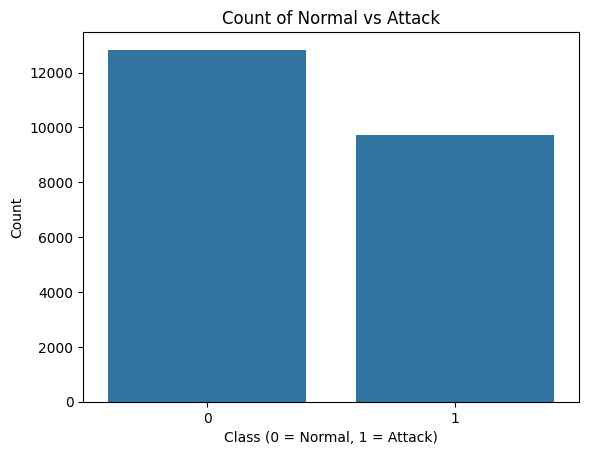

In [42]:
sns.countplot(x='attack', data=test_df)
plt.title("Count of Normal vs Attack")
plt.xlabel("Class (0 = Normal, 1 = Attack)")
plt.ylabel("Count")

In [43]:
print("Class distribution: {}".format(Counter(y_test)))

Class distribution: Counter({0: 12833, 1: 9711})


In [44]:
X_transformed_test = scaler.transform(X_test)

# Implementing Classification Models

* **Tree-based Models:** Random Forest,  LightGBM

# Initialize and Train the Machine Learning (ML) Models

Checking data shapes...
X_transformed shape: (125973, 38)
y shape: (125973,)
X_transformed_test shape: (22544, 38)
y_test shape: (22544,)

Class distribution in training data:
attack
1    53.46%
0    46.54%
Name: proportion, dtype: object

Class distribution in test data:
attack
0    56.92%
1    43.08%
Name: proportion, dtype: object


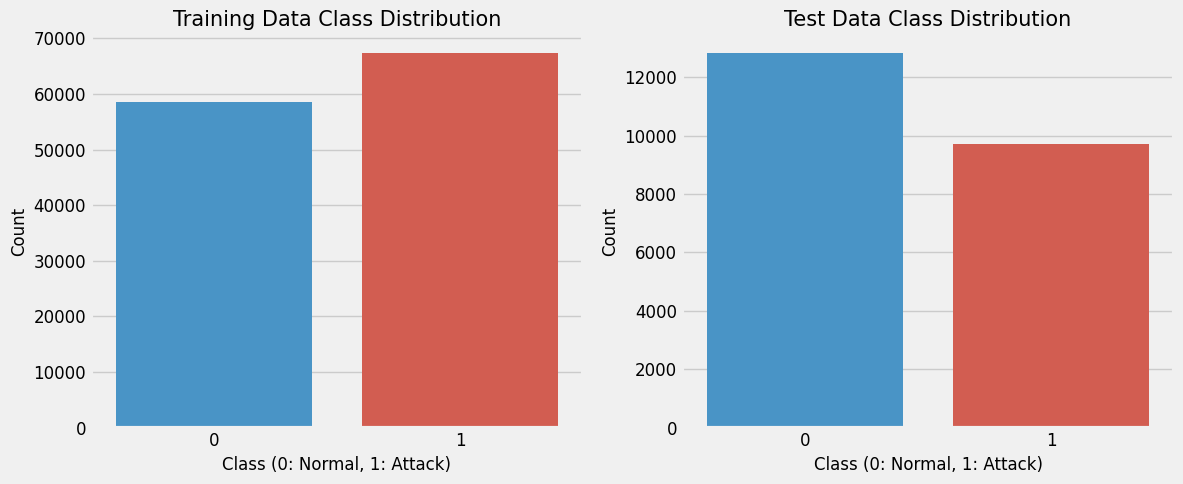


===== Random Forest Model Training with Hyperparameter Tuning =====
Performing hyperparameter tuning for Random Forest...
Fitting 3 folds for each of 25 candidates, totalling 75 fits

Best Random Forest parameters found: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'criterion': 'entropy', 'class_weight': 'balanced', 'bootstrap': False}
Best score: 0.9997
Tuning time: 382.75 seconds

===== Random Forest Model Performance =====
Accuracy: 0.8100
Precision: 0.7016
Recall: 0.9723
F1 Score: 0.8151
AUC-ROC: 0.9794

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.69      0.80     12833
           1       0.70      0.97      0.82      9711

    accuracy                           0.81     22544
   macro avg       0.84      0.83      0.81     22544
weighted avg       0.85      0.81      0.81     22544



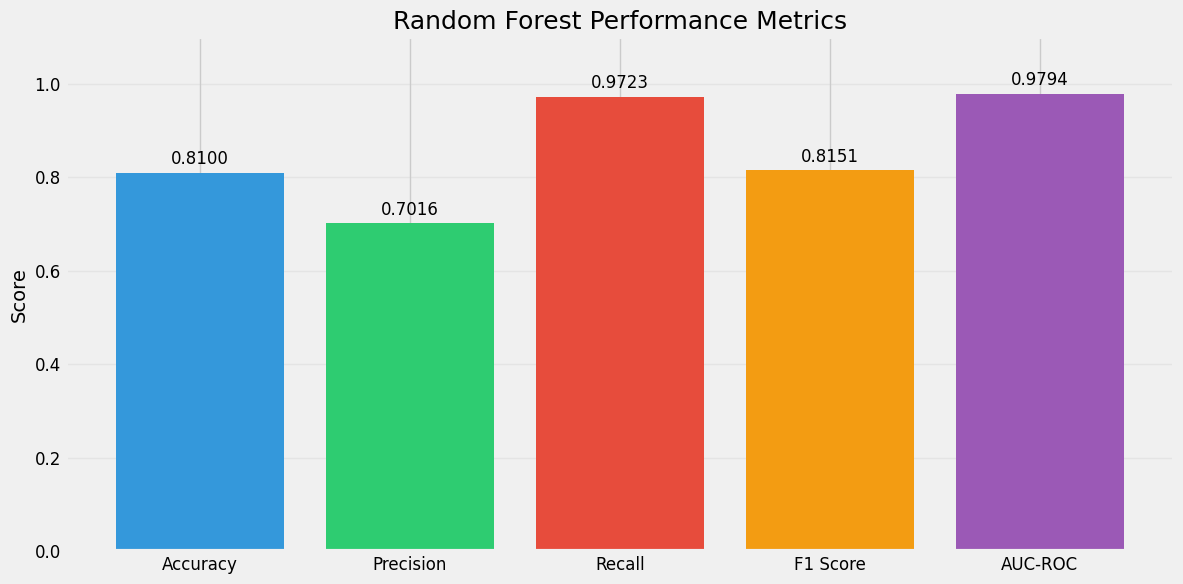

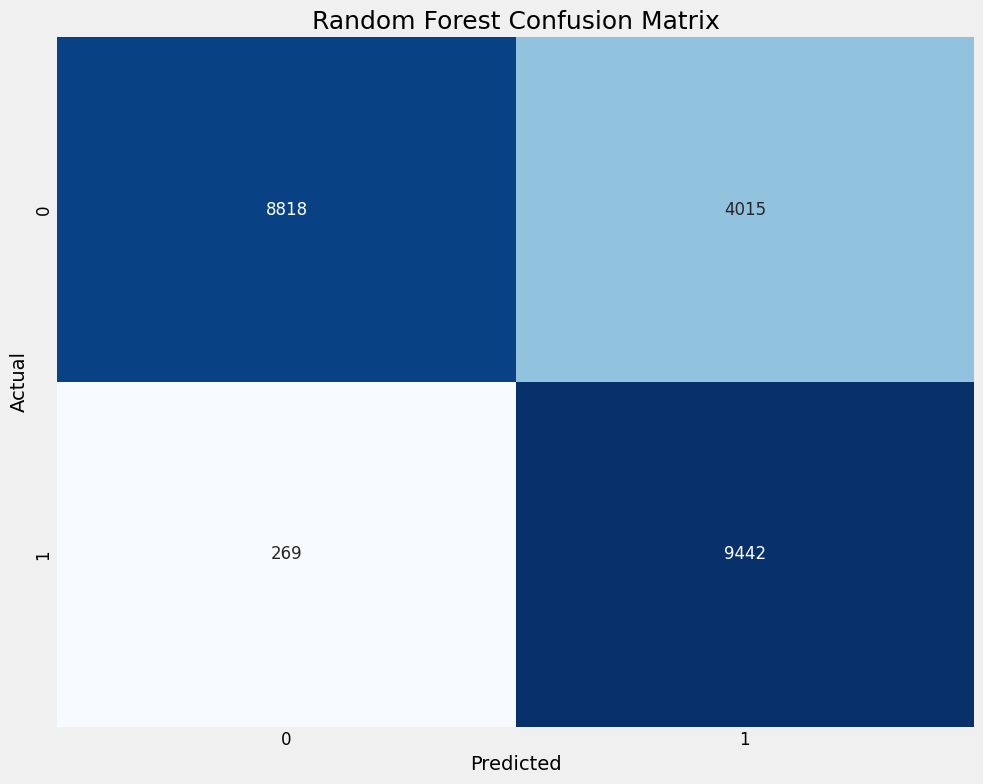

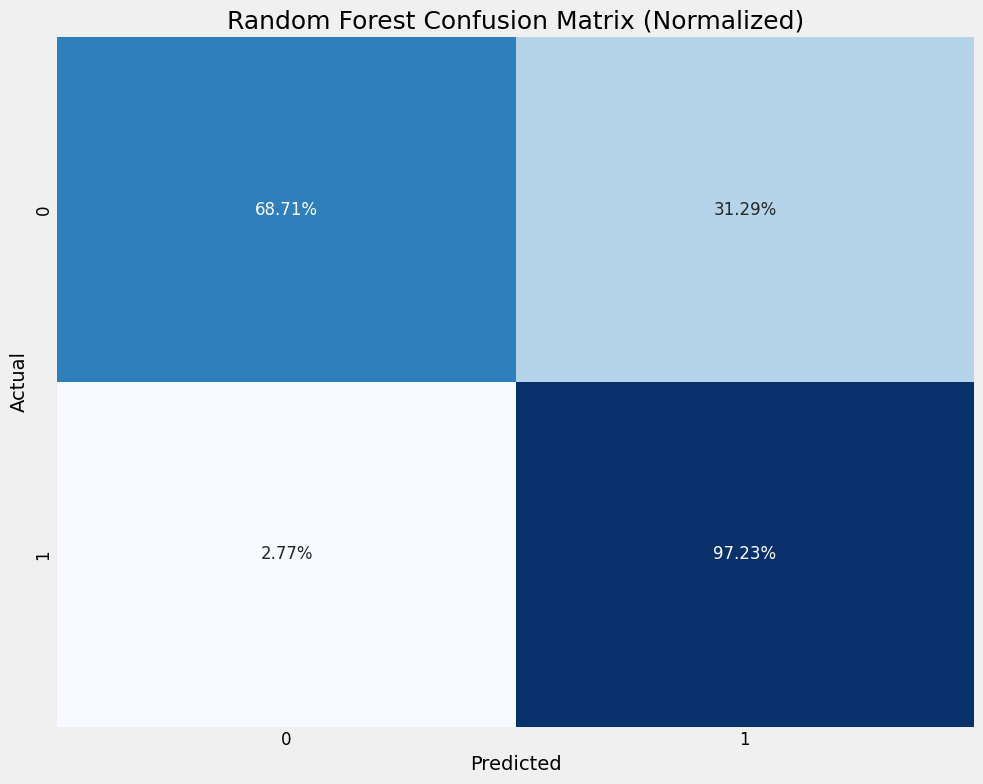

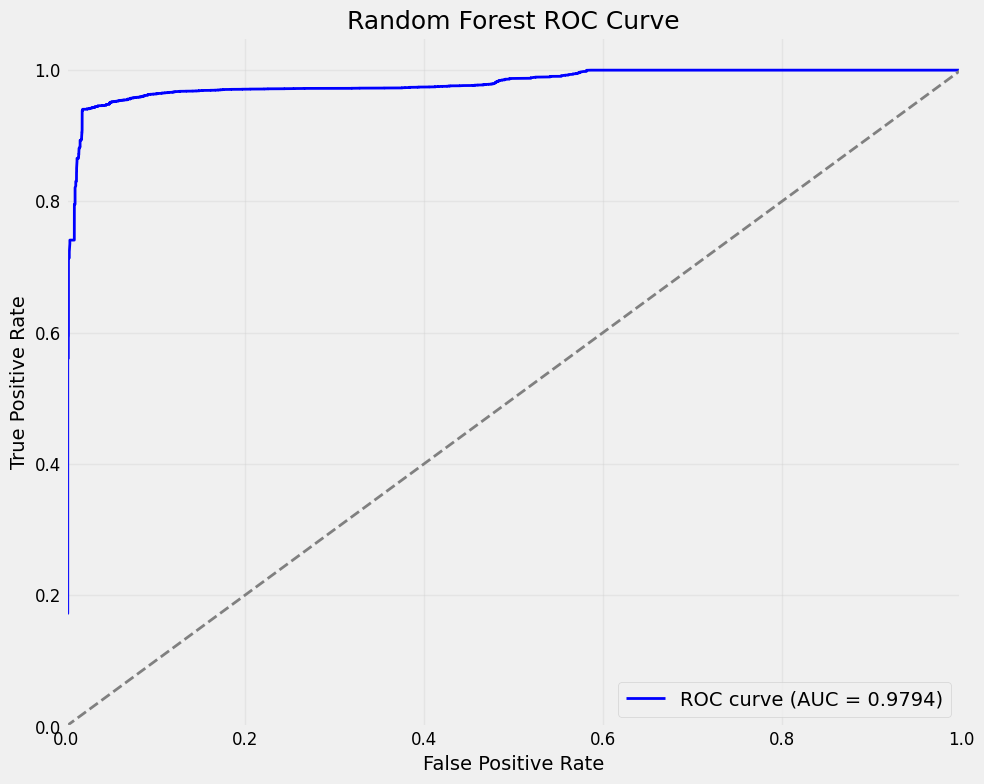

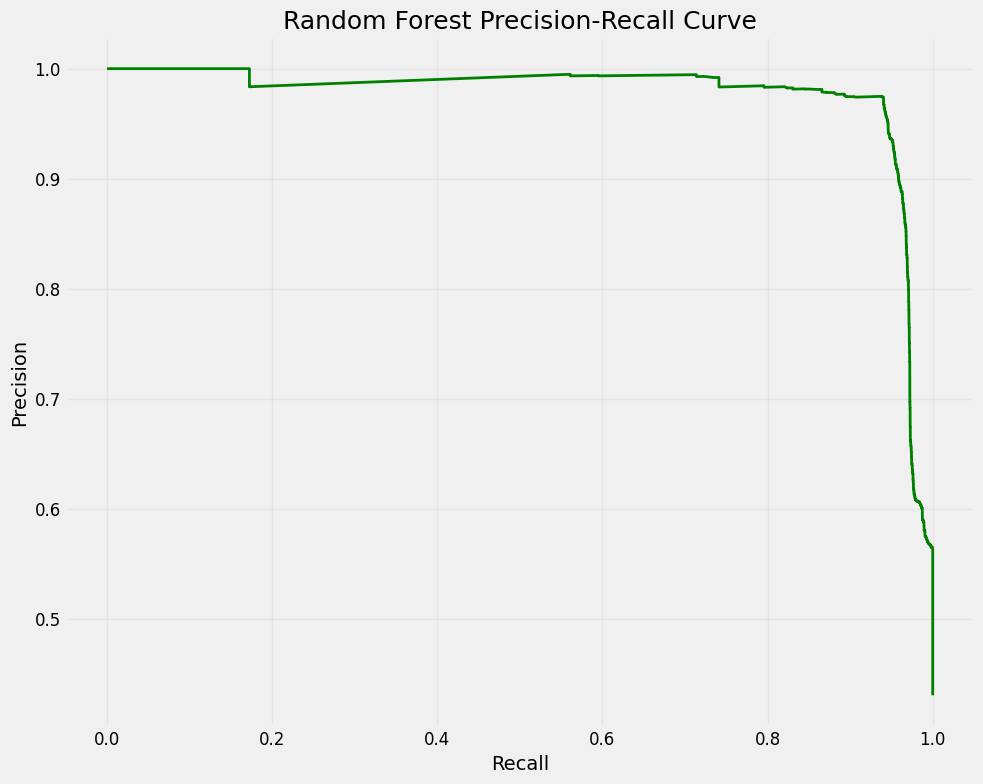

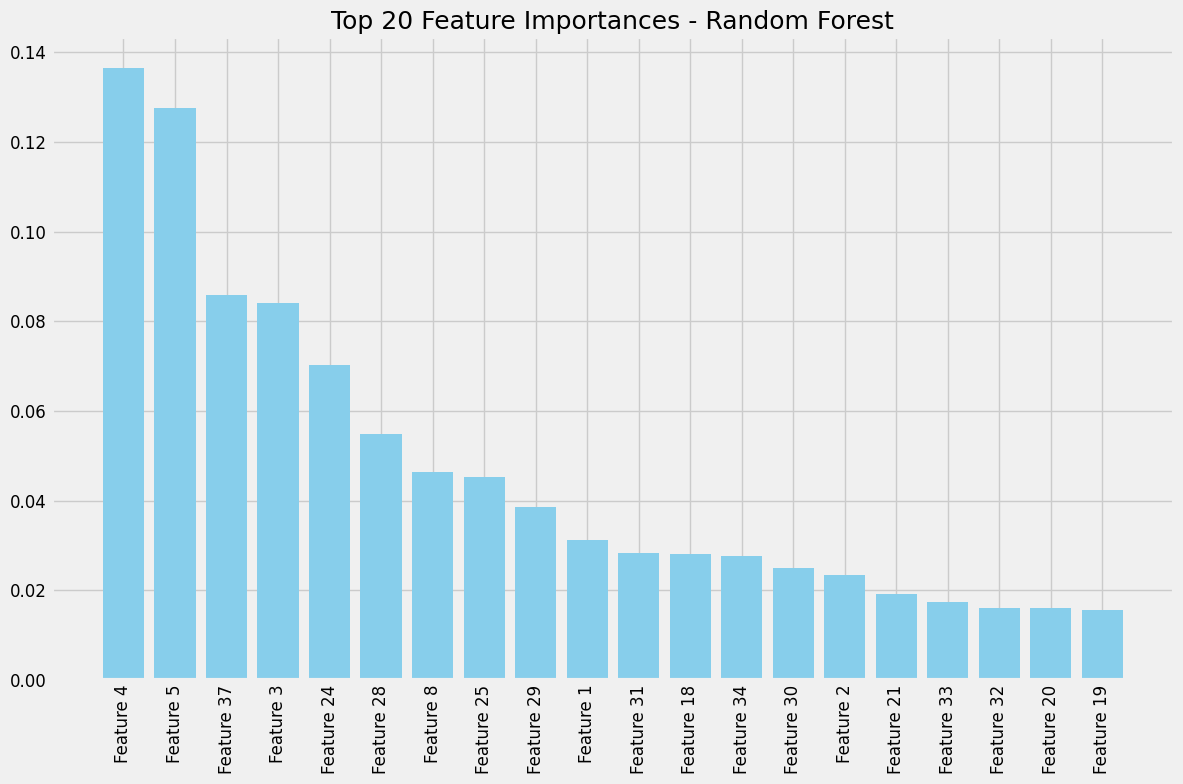


===== LightGBM Model Training with Hyperparameter Tuning =====
Performing hyperparameter tuning for LightGBM...
Fitting 3 folds for each of 25 candidates, totalling 75 fits
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Info] Number of positive: 67343, number of negative: 58630
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.050480 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3204
[LightGBM] [Info] Number of data points in the train set: 125973, number of used features: 37
[LightGBM] [Info] Using GOSS
[LightGBM]

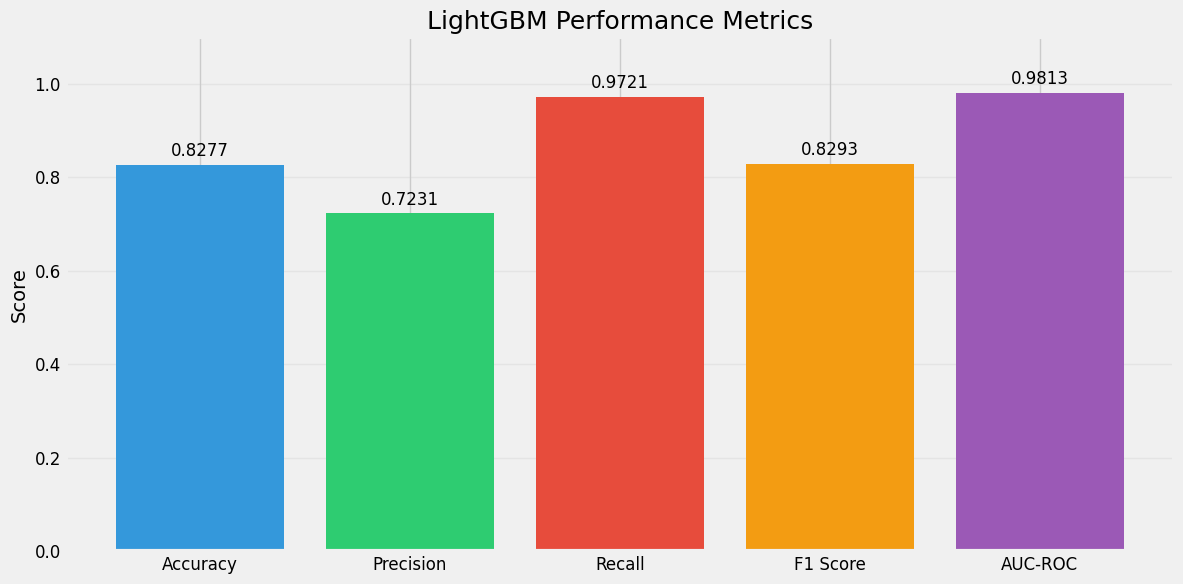

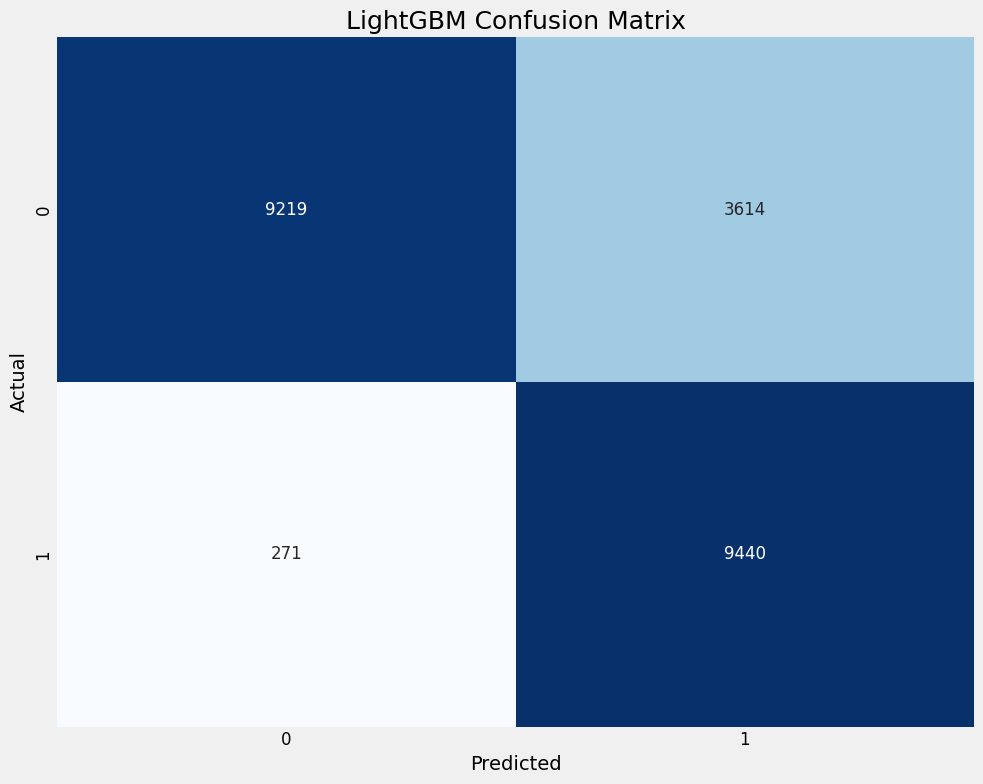

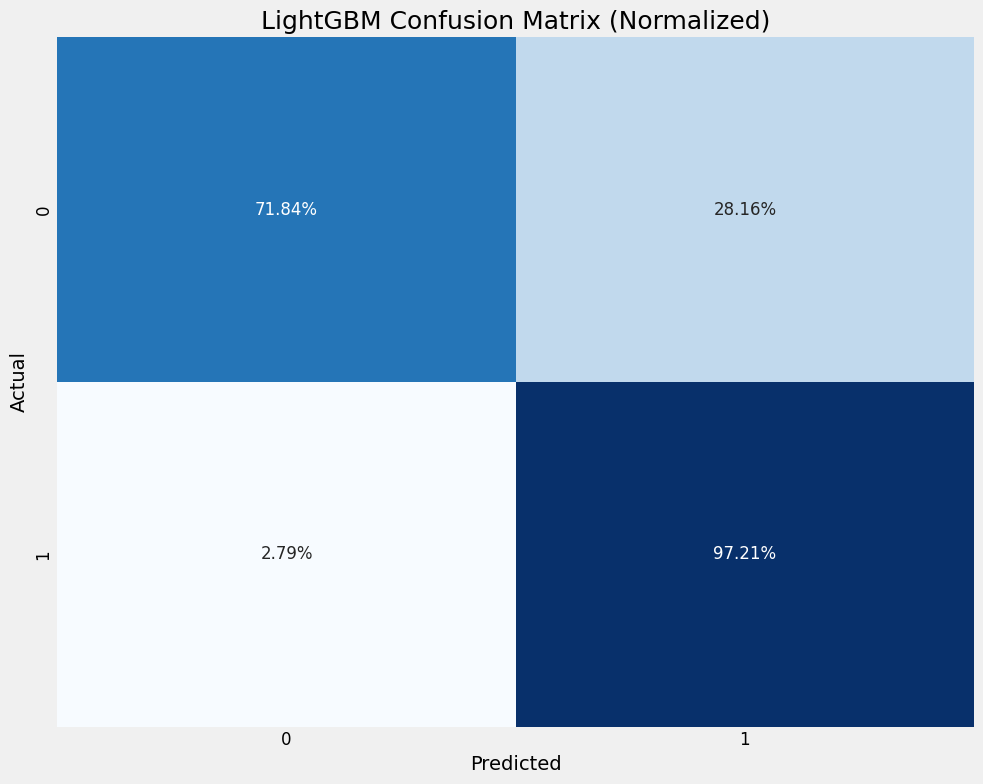

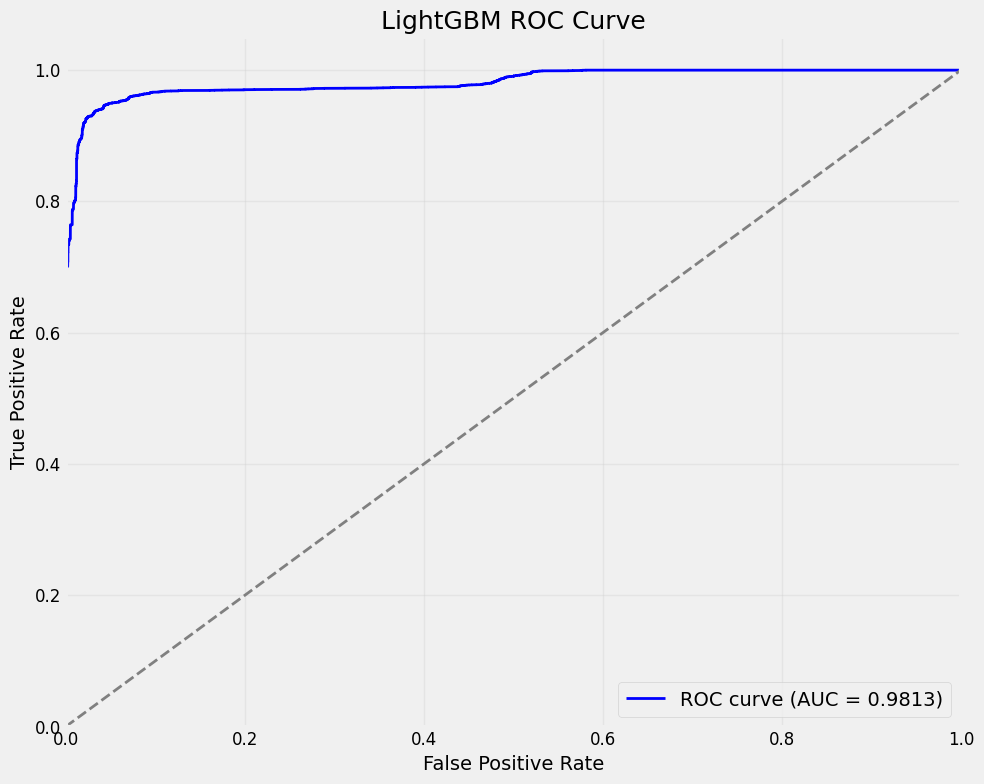

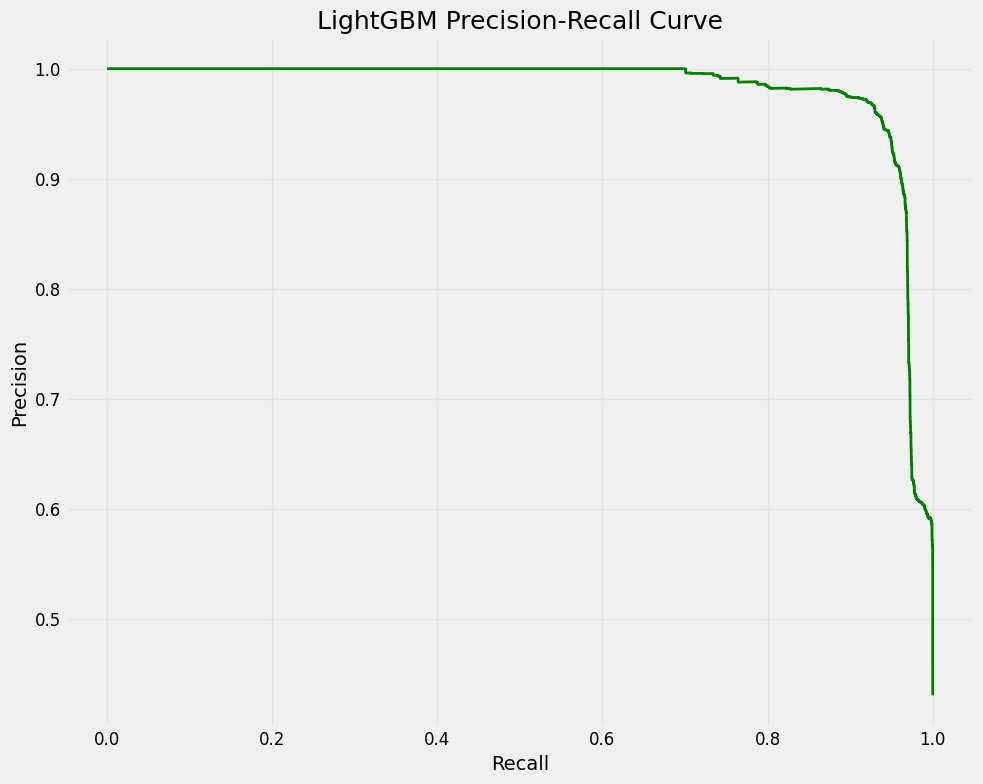

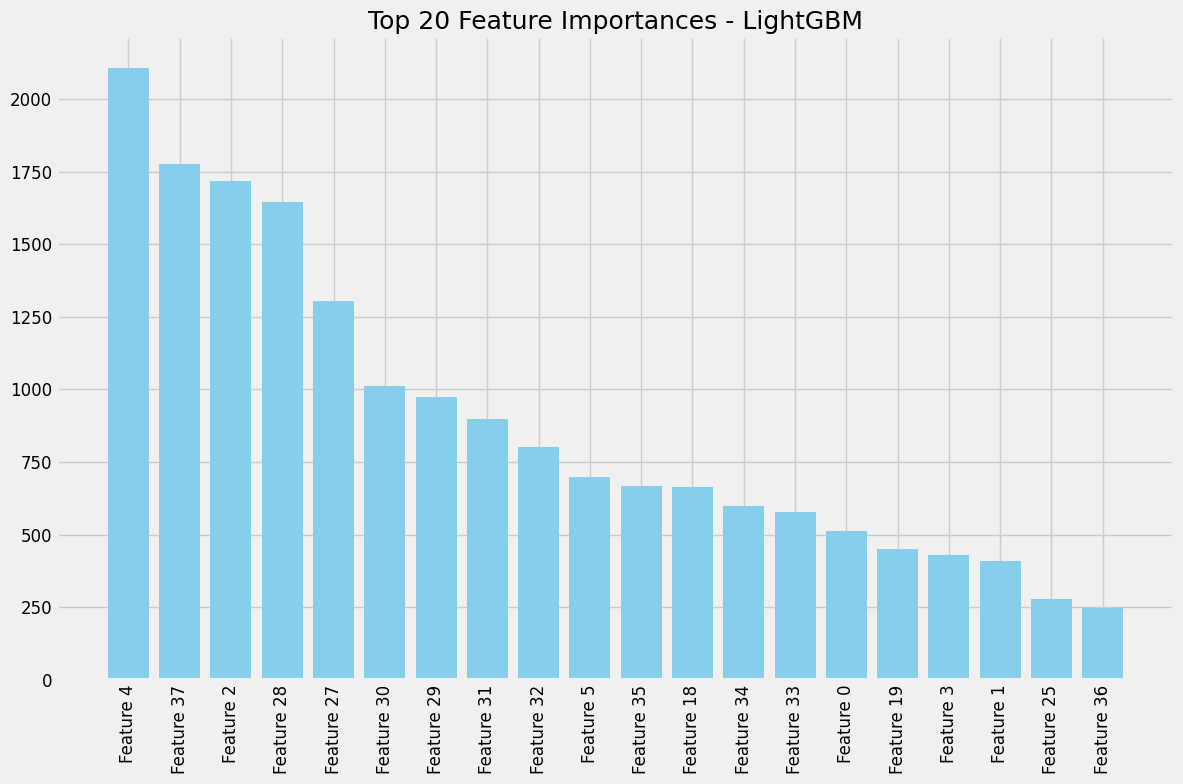


===== SHAP Analysis for Model Explainability =====
Running SHAP analysis for Random Forest...


<Figure size 1200x1000 with 0 Axes>

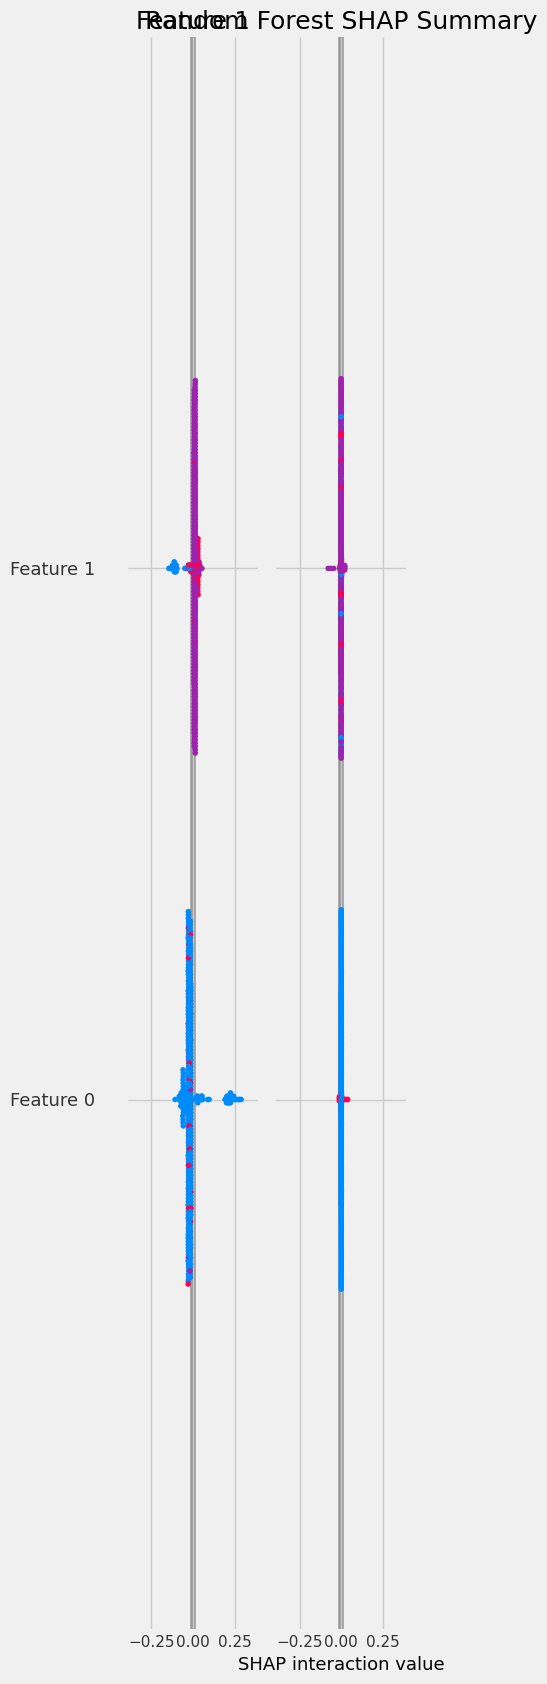


Running SHAP analysis for LightGBM...


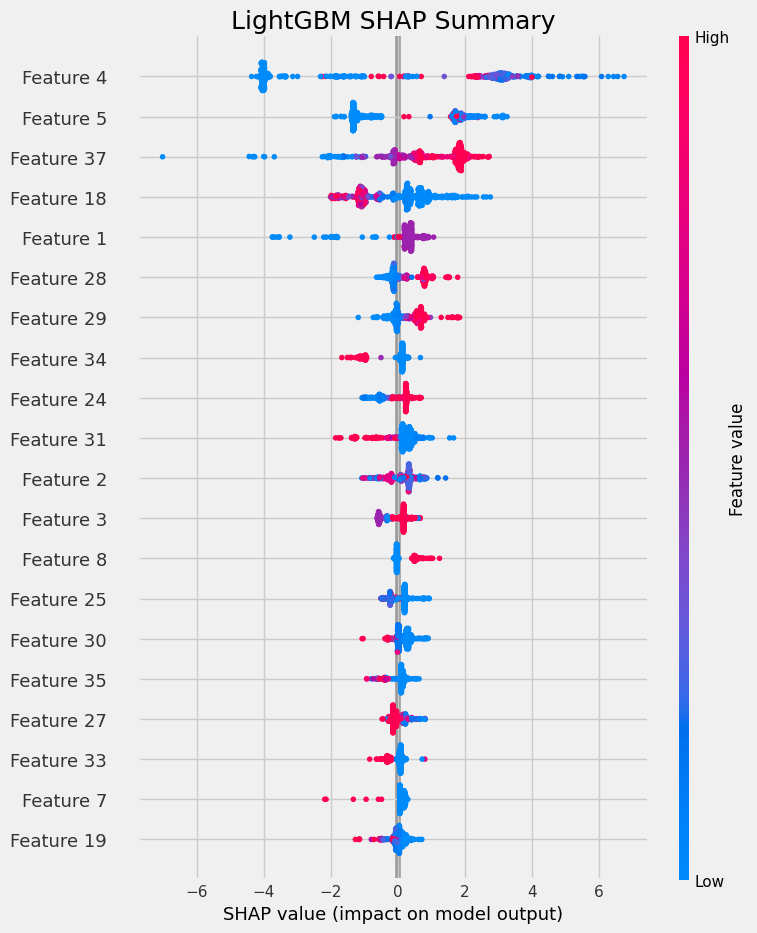


===== Model Comparison =====


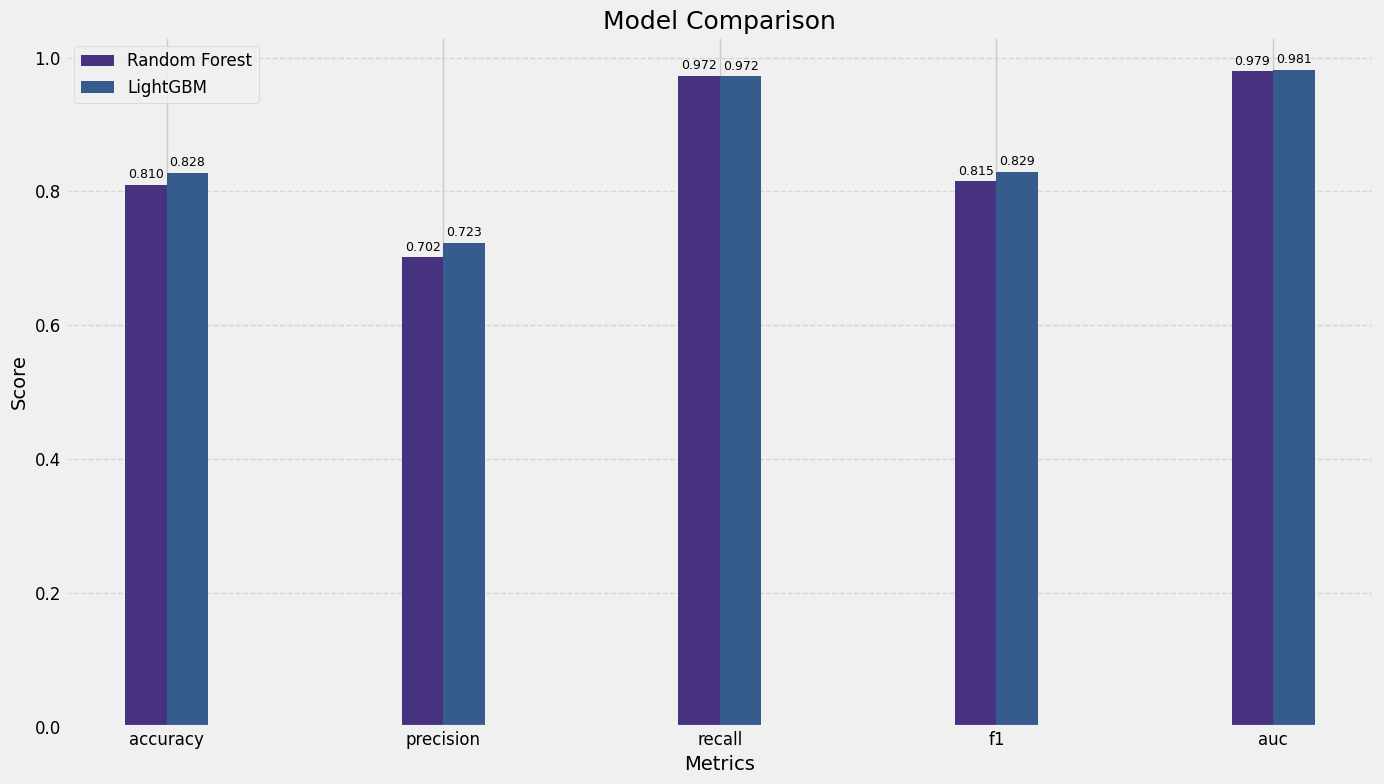

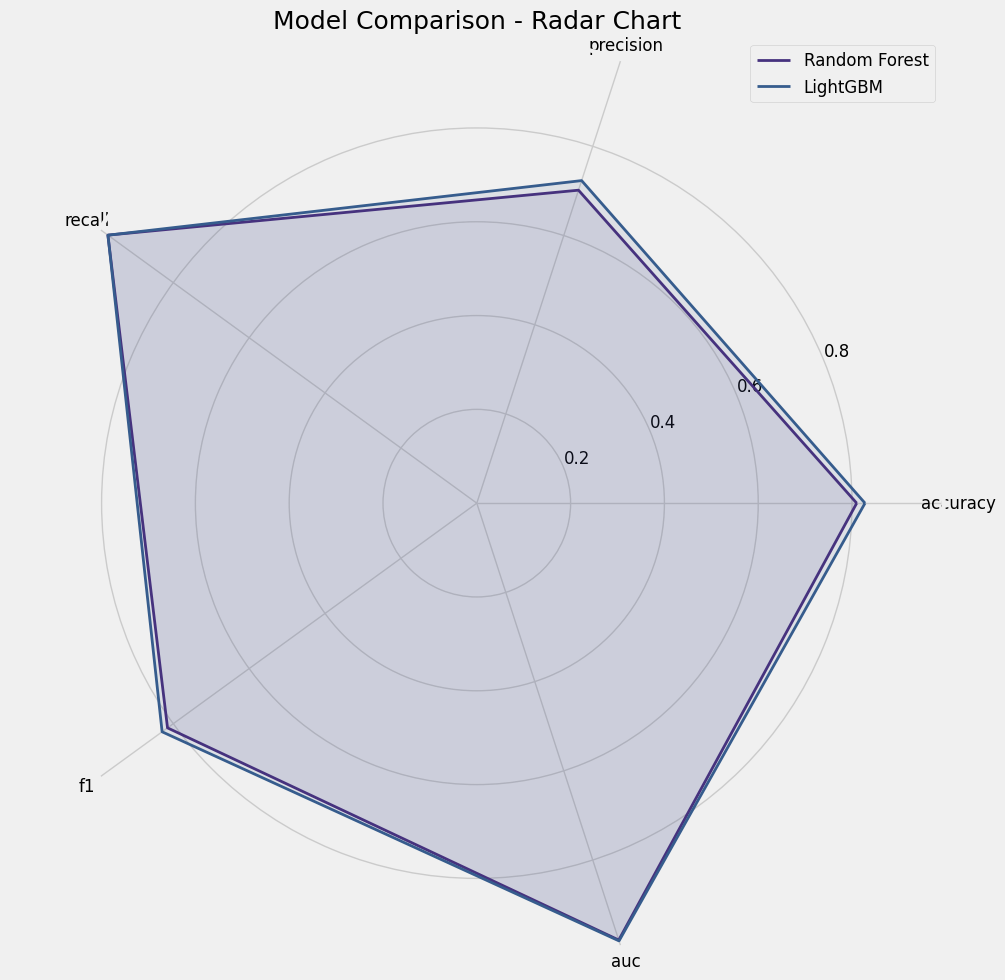


===== Prediction Comparison =====
   Actual  RF_Predicted  RF_Probability  LGBM_Predicted  LGBM_Probability  \
0       0             0        0.000000               0          0.000036   
1       0             0        0.000000               0          0.000038   
2       1             1        0.972327               1          0.999746   
3       0             0        0.228402               0          0.005995   
4       0             1        0.503985               1          0.706381   
5       1             1        0.992327               1          0.999973   
6       1             1        0.975000               1          0.999911   
7       0             1        0.905597               1          0.999050   
8       1             1        0.992327               1          0.999973   
9       0             1        0.556684               1          0.599553   

   RF_Correct  LGBM_Correct  Both_Correct  Both_Incorrect  
0        True          True          True           False

In [45]:
# Set styling for all plots
plt.style.use('fivethirtyeight')
sns.set_palette("viridis")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

# 1. Define functions for visualization and evaluation
def plot_confusion_matrix(y_true, y_pred, title):
    """Plot confusion matrix with percentages"""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'{title} Confusion Matrix', fontsize=18)
    plt.ylabel('Actual', fontsize=14)
    plt.xlabel('Predicted', fontsize=14)
    plt.tight_layout()
    plt.show()

    # Calculate percentages
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', cbar=False)
    plt.title(f'{title} Confusion Matrix (Normalized)', fontsize=18)
    plt.ylabel('Actual', fontsize=14)
    plt.xlabel('Predicted', fontsize=14)
    plt.tight_layout()
    plt.show()

def plot_roc_curve(y_true, y_prob, title):
    """Plot ROC curve"""
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    plt.figure(figsize=(10, 8))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=14)
    plt.ylabel('True Positive Rate', fontsize=14)
    plt.title(f'{title} ROC Curve', fontsize=18)
    plt.legend(loc="lower right", fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_precision_recall_curve(y_true, y_prob, title):
    """Plot precision-recall curve"""
    precision, recall, _ = precision_recall_curve(y_true, y_prob)

    plt.figure(figsize=(10, 8))
    plt.plot(recall, precision, color='green', lw=2)
    plt.xlabel('Recall', fontsize=14)
    plt.ylabel('Precision', fontsize=14)
    plt.title(f'{title} Precision-Recall Curve', fontsize=18)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def evaluate_model(y_true, y_pred, y_prob, title):
    """Evaluate model performance with various metrics"""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    print(f"\n===== {title} Model Performance =====")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC-ROC: {auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Create a bar chart of metrics
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
    values = [acc, prec, rec, f1, auc]

    plt.figure(figsize=(12, 6))
    bars = plt.bar(metrics, values, color=['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6'])

    # Add value labels on top of bars
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.4f}', ha='center', va='bottom', fontsize=12)

    plt.ylim(0, 1.1)
    plt.title(f'{title} Performance Metrics', fontsize=18)
    plt.ylabel('Score', fontsize=14)
    plt.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1, 'auc': auc}

def plot_feature_importance(model, X, title, top_n=20):
    """Plot feature importance"""
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        indices = np.argsort(importances)[::-1]

        # Get feature names if X is a DataFrame, otherwise use indices
        if isinstance(X, pd.DataFrame):
            feature_names = X.columns
        else:
            feature_names = [f'Feature {i}' for i in range(X.shape[1])]

        plt.figure(figsize=(12, 8))
        plt.title(f'Top {top_n} Feature Importances - {title}', fontsize=18)
        plt.bar(range(min(top_n, len(importances))),
                importances[indices][:top_n],
                color='skyblue')
        plt.xticks(range(min(top_n, len(importances))),
                   [feature_names[i] for i in indices[:top_n]],
                   rotation=90)
        plt.tight_layout()
        plt.show()

        # Return the top features and their importance scores
        top_features = [(feature_names[i], importances[i]) for i in indices[:top_n]]
        return top_features
    else:
        print(f"The {title} model doesn't have feature_importances_ attribute.")
        return None

def plot_permutation_importance(model, X, y, title, top_n=20):
    """Plot permutation importance"""
    perm_importance = permutation_importance(model, X, y, n_repeats=10, random_state=42)

    # Get feature names if X is a DataFrame, otherwise use indices
    if isinstance(X, pd.DataFrame):
        feature_names = X.columns
    else:
        feature_names = [f'Feature {i}' for i in range(X.shape[1])]

    sorted_idx = perm_importance.importances_mean.argsort()[::-1]

    plt.figure(figsize=(12, 8))
    plt.title(f'Top {top_n} Permutation Importances - {title}', fontsize=18)
    plt.bar(range(min(top_n, len(sorted_idx))),
            perm_importance.importances_mean[sorted_idx][:top_n],
            yerr=perm_importance.importances_std[sorted_idx][:top_n],
            color='lightgreen')
    plt.xticks(range(min(top_n, len(sorted_idx))),
               [feature_names[i] for i in sorted_idx[:top_n]],
               rotation=90)
    plt.tight_layout()
    plt.show()

def plot_shap_summary(model, X, title, max_display=20):
    """Plot SHAP summary"""
    try:
        # For LightGBM native models
        if isinstance(model, lgb.Booster):
            explainer = shap.TreeExplainer(model)
        # For sklearn-based models
        else:
            explainer = shap.TreeExplainer(model)

        # Convert X to dense format if it's sparse
        if hasattr(X, 'toarray'):
            X_sample = X.toarray()
            # Limit to 500 samples for computational efficiency
            if X_sample.shape[0] > 500:
                X_sample = X_sample[:500]
        else:
            X_sample = X
            if X_sample.shape[0] > 500:
                X_sample = X_sample[:500]

        shap_values = explainer.shap_values(X_sample)

        # If shap_values is a list (for multi-class), take the values for class 1
        if isinstance(shap_values, list):
            shap_values = shap_values[1] if len(shap_values) > 1 else shap_values[0]

        plt.figure(figsize=(12, 10))
        shap.summary_plot(shap_values, X_sample,
                          feature_names=X.columns if isinstance(X, pd.DataFrame) else None,
                          max_display=max_display, show=False)
        plt.title(f'{title} SHAP Summary', fontsize=18)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"SHAP visualization failed: {str(e)}")

def plot_learning_curves(train_sizes, train_scores, test_scores, title):
    """Plot learning curves"""
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training score')
    plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

    plt.plot(train_sizes, test_mean, color='green', marker='s', markersize=5, label='Validation score')
    plt.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

    plt.title(f'{title} Learning Curves', fontsize=18)
    plt.xlabel('Training Examples', fontsize=14)
    plt.ylabel('Score', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='lower right', fontsize=12)
    plt.tight_layout()
    plt.show()

def compare_models(model_metrics, chart_type='bar'):
    """Compare models visually"""
    metrics = list(list(model_metrics.values())[0].keys())
    models = list(model_metrics.keys())

    if chart_type == 'bar':
        # Create grouped bar chart
        fig, ax = plt.subplots(figsize=(14, 8))
        bar_width = 0.15
        index = np.arange(len(metrics))

        for i, model in enumerate(models):
            values = [model_metrics[model][metric] for metric in metrics]
            ax.bar(index + i * bar_width, values, bar_width, label=model)

        ax.set_xlabel('Metrics', fontsize=14)
        ax.set_ylabel('Score', fontsize=14)
        ax.set_title('Model Comparison', fontsize=18)
        ax.set_xticks(index + bar_width * (len(models) - 1) / 2)
        ax.set_xticklabels(metrics)
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.7, axis='y')

        # Add values on top of bars
        for i, model in enumerate(models):
            values = [model_metrics[model][metric] for metric in metrics]
            for j, v in enumerate(values):
                ax.text(j + i * bar_width, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)

        plt.tight_layout()
        plt.show()

    elif chart_type == 'radar':
        # Create radar chart
        metrics_count = len(metrics)
        angles = np.linspace(0, 2 * np.pi, metrics_count, endpoint=False).tolist()
        angles += angles[:1]  # Close the circle

        fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

        for model in models:
            values = [model_metrics[model][metric] for metric in metrics]
            values += values[:1]  # Close the circle
            ax.plot(angles, values, linewidth=2, label=model)
            ax.fill(angles, values, alpha=0.1)

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(metrics)
        ax.set_title('Model Comparison - Radar Chart', fontsize=18)
        ax.grid(True)
        plt.legend(loc='upper right')
        plt.tight_layout()
        plt.show()

# 2. Data exploration
print("Checking data shapes...")
print(f"X_transformed shape: {X_transformed.shape}")
print(f"y shape: {y.shape}")
print(f"X_transformed_test shape: {X_transformed_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Check class distribution
print("\nClass distribution in training data:")
print(pd.Series(y).value_counts(normalize=True).map(lambda x: f"{x:.2%}"))

print("\nClass distribution in test data:")
print(pd.Series(y_test).value_counts(normalize=True).map(lambda x: f"{x:.2%}"))

# Visualize class distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(x=y, palette=['#3498db', '#e74c3c'])
plt.title('Training Data Class Distribution', fontsize=15)
plt.xlabel('Class (0: Normal, 1: Attack)', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.subplot(1, 2, 2)
sns.countplot(x=y_test, palette=['#3498db', '#e74c3c'])
plt.title('Test Data Class Distribution', fontsize=15)
plt.xlabel('Class (0: Normal, 1: Attack)', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

# 3. Random Forest Model with Hyperparameter Tuning
print("\n===== Random Forest Model Training with Hyperparameter Tuning =====")

# Define the hyperparameter grid
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt'],
    'bootstrap': [True, False],
    'class_weight': [None, 'balanced', 'balanced_subsample'],
    'criterion': ['gini', 'entropy']
}

# Initialize Random Forest
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# RandomizedSearchCV to find best hyperparameters
print("Performing hyperparameter tuning for Random Forest...")
rf_random = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=rf_param_grid,
    n_iter=25,  # Number of parameter settings sampled
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    scoring='f1'
)

start_time = time.time()
rf_random.fit(X_transformed, y)
rf_tuning_time = time.time() - start_time

print(f"\nBest Random Forest parameters found: {rf_random.best_params_}")
print(f"Best score: {rf_random.best_score_:.4f}")
print(f"Tuning time: {rf_tuning_time:.2f} seconds")

# Train the best Random Forest model
best_rf = rf_random.best_estimator_

# Make predictions
rf_y_pred = best_rf.predict(X_transformed_test)S
rf_y_prob = best_rf.predict_proba(X_transformed_test)[:, 1]

# Evaluate Random Forest
rf_metrics = evaluate_model(y_test, rf_y_pred, rf_y_prob, "Random Forest")

# Visualize Random Forest results
plot_confusion_matrix(y_test, rf_y_pred, "Random Forest")
plot_roc_curve(y_test, rf_y_prob, "Random Forest")
plot_precision_recall_curve(y_test, rf_y_prob, "Random Forest")
rf_features = plot_feature_importance(best_rf, X_transformed, "Random Forest")

# 4. LightGBM Model with Hyperparameter Tuning
print("\n===== LightGBM Model Training with Hyperparameter Tuning =====")

# Convert data to LightGBM format if needed
if isinstance(X_transformed, pd.DataFrame):
    lgb_train = lgb.Dataset(X_transformed, y)
    lgb_test = lgb.Dataset(X_transformed_test, y_test, reference=lgb_train)
else:
    lgb_train = lgb.Dataset(X_transformed, y)
    lgb_test = lgb.Dataset(X_transformed_test, y_test, reference=lgb_train)

# Define LightGBM hyperparameter grid
lgb_param_grid = {
    'boosting_type': ['gbdt', 'dart', 'goss'],
    'num_leaves': [100, 150],
    'max_depth': [-1, 20, 25],
    'learning_rate': [0.01, 0.05],
    'n_estimators': [100, 200],
    'subsample': [0.6, 0.7],
    'colsample_bytree': [0.6, 0.7],
    'reg_alpha': [0.1, 0.5],
    'reg_lambda': [0.1, 0.5],
    'min_child_samples': [10, 20],
    'class_weight': [None, 'balanced']
}

# Convert LightGBM params to sklearn estimator for RandomizedSearchCV
lgb_model = lgb.LGBMClassifier(
    objective='binary',
    metric='binary_logloss',
    random_state=42,
    n_jobs=-1
)

# RandomizedSearchCV to find best hyperparameters
print("Performing hyperparameter tuning for LightGBM...")
lgb_random = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=lgb_param_grid,
    n_iter=25,  # Number of parameter settings sampled
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    scoring='f1'
)

start_time = time.time()
lgb_random.fit(X_transformed, y)
lgb_tuning_time = time.time() - start_time

print(f"\nBest LightGBM parameters found: {lgb_random.best_params_}")
print(f"Best score: {lgb_random.best_score_:.4f}")
print(f"Tuning time: {lgb_tuning_time:.2f} seconds")

# Train the best LightGBM model
best_lgb = lgb_random.best_estimator_

# Make predictions
lgb_y_pred = best_lgb.predict(X_transformed_test)
lgb_y_prob = best_lgb.predict_proba(X_transformed_test)[:, 1]

# Evaluate LightGBM
lgb_metrics = evaluate_model(y_test, lgb_y_pred, lgb_y_prob, "LightGBM")

# Visualize LightGBM results
plot_confusion_matrix(y_test, lgb_y_pred, "LightGBM")
plot_roc_curve(y_test, lgb_y_prob, "LightGBM")
plot_precision_recall_curve(y_test, lgb_y_prob, "LightGBM")
lgb_features = plot_feature_importance(best_lgb, X_transformed, "LightGBM")

# SHAP analysis for explainability
print("\n===== SHAP Analysis for Model Explainability =====")
print("Running SHAP analysis for Random Forest...")
plot_shap_summary(best_rf, X_transformed, "Random Forest")

print("\nRunning SHAP analysis for LightGBM...")
plot_shap_summary(best_lgb, X_transformed, "LightGBM")

# 5. Compare model performance
all_metrics = {
    'Random Forest': rf_metrics,
    'LightGBM': lgb_metrics
}

print("\n===== Model Comparison =====")
compare_models(all_metrics, chart_type='bar')
compare_models(all_metrics, chart_type='radar')

# 6. Create comparison dataframe of test data with actual vs predicted
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'RF_Predicted': rf_y_pred,
    'RF_Probability': rf_y_prob,
    'LGBM_Predicted': lgb_y_pred,
    'LGBM_Probability': lgb_y_prob
})

# Add correct/incorrect columns
comparison_df['RF_Correct'] = comparison_df['Actual'] == comparison_df['RF_Predicted']
comparison_df['LGBM_Correct'] = comparison_df['Actual'] == comparison_df['LGBM_Predicted']
comparison_df['Both_Correct'] = comparison_df['RF_Correct'] & comparison_df['LGBM_Correct']
comparison_df['Both_Incorrect'] = ~comparison_df['RF_Correct'] & ~comparison_df['LGBM_Correct']

print("\n===== Prediction Comparison =====")
print(comparison_df.head(10))

# Analysis of where models agree/disagree
agreement = (comparison_df['RF_Predicted'] == comparison_df['LGBM_Predicted']).mean()
print(f"\nModel agreement: {agreement:.4f} ({agreement*100:.2f}%)")

agreement_correct = comparison_df[comparison_df['RF_Predicted'] == comparison_df['LGBM_Predicted']]['Both_Correct'].mean()
print(f"When models agree, accuracy: {agreement_correct:.4f} ({agreement_correct*100:.2f}%)")


# Return final evaluation
print("\n===== Final Recommendation =====")
if rf_metrics['f1'] > lgb_metrics['f1']:
    print(f"Random Forest model performed better with F1 score of {rf_metrics['f1']:.4f} vs LightGBM's {lgb_metrics['f1']:.4f}")
    print("Recommendation: Use the Random Forest model for production")
elif lgb_metrics['f1'] > rf_metrics['f1']:
    print(f"LightGBM model performed better with F1 score of {lgb_metrics['f1']:.4f} vs Random Forest's {rf_metrics['f1']:.4f}")
    print("Recommendation: Use the LightGBM model for production")
else:
    print(f"Both models performed equally well with F1 score of {rf_metrics['f1']:.4f}")
    print("Recommendation: Consider an ensemble of both models for production")